<a href="https://colab.research.google.com/github/Dylanrgyg/XAI/blob/main/WQF7009_Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [26]:
from pathlib import Path
import zipfile
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

BASE_DIR = Path("/content")
zip_files = list(BASE_DIR.glob("*.zip"))

print("Uploaded ZIP files:")
for f in zip_files:
    print(f.name, f"{f.stat().st_size / 1024**2:.2f} MB")

if len(zip_files) == 1:
    ZIP_PATH = zip_files[0]
else:
    print("Please manually select the correct ZIP file.")

Uploaded ZIP files:
archive.zip 397.84 MB


In [27]:
EXTRACT_DIR = Path("/content/alzheimer_dataset")
EXTRACT_DIR.mkdir(exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(EXTRACT_DIR)

print("Dataset extracted to:", EXTRACT_DIR)

Dataset extracted to: /content/alzheimer_dataset


In [28]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

for root, dirs, files in os.walk(EXTRACT_DIR):
    level = len(Path(root).relative_to(EXTRACT_DIR).parts)

    if level <= 3:
        print("  " * level + Path(root).name + "/")

# Locate training and testing directories
split_dirs = {}

for path in EXTRACT_DIR.rglob("*"):
    if path.is_dir() and path.name.lower() in {
        "train", "training", "test", "testing"
    }:
        split_dirs[path.name] = path

# Count images in each class
results = []

for split_name, split_path in split_dirs.items():
    for class_dir in split_path.iterdir():
        if class_dir.is_dir():
            count = sum(
                1 for f in class_dir.rglob("*")
                if f.suffix.lower() in IMAGE_EXTENSIONS
            )

            results.append({
                "Dataset": split_name,
                "Class": class_dir.name,
                "Image Count": count
            })

df = pd.DataFrame(results)
display(df)

alzheimer_dataset/
  combined_images/
    ModerateDemented/
    MildDemented/
    VeryMildDemented/
    NonDemented/


""


In [29]:
from pathlib import Path
from PIL import Image
import pandas as pd

DATA_DIR = Path("/content/alzheimer_dataset/combined_images")

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

results = []

for class_dir in sorted(DATA_DIR.iterdir()):
    if not class_dir.is_dir():
        continue

    images = [
        f for f in class_dir.rglob("*")
        if f.suffix.lower() in IMAGE_EXTENSIONS
    ]

    valid_count = 0
    corrupted_count = 0

    for img_path in images:
        try:
            with Image.open(img_path) as img:
                img.verify()
            valid_count += 1
        except Exception:
            corrupted_count += 1

    results.append({
        "Class": class_dir.name,
        "Total Images": len(images),
        "Valid Images": valid_count,
        "Corrupted Images": corrupted_count
    })

df = pd.DataFrame(results)
display(df)

print("Total images:", df["Total Images"].sum())
print("Valid images:", df["Valid Images"].sum())
print("Corrupted images:", df["Corrupted Images"].sum())

,Class,Total Images,Valid Images,Corrupted Images
0,MildDemented,10000,10000,0
1,ModerateDemented,10000,10000,0
2,NonDemented,12800,12800,0
3,VeryMildDemented,11200,11200,0


Total images: 44000
Valid images: 44000
Corrupted images: 0


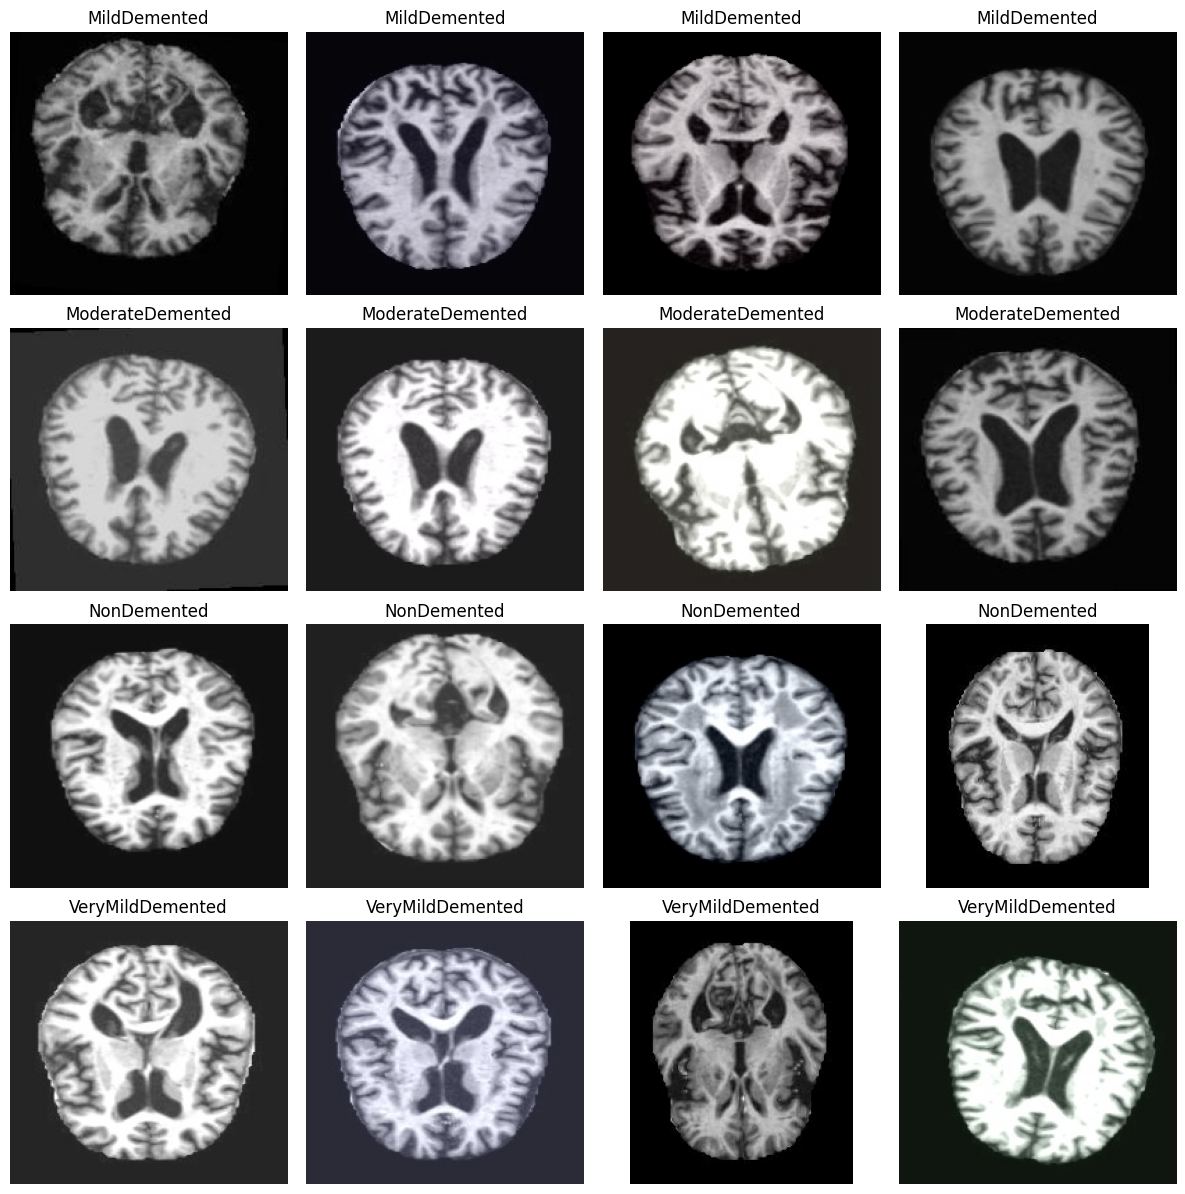

In [30]:
import matplotlib.pyplot as plt
import random

classes = sorted([p for p in DATA_DIR.iterdir() if p.is_dir()])

fig, axes = plt.subplots(4, 4, figsize=(12, 12))

for row, class_dir in enumerate(classes):
    images = [
        f for f in class_dir.rglob("*")
        if f.suffix.lower() in IMAGE_EXTENSIONS
    ]

    samples = random.sample(images, min(4, len(images)))

    for col, img_path in enumerate(samples):
        with Image.open(img_path) as img:
            axes[row, col].imshow(img.convert("RGB"))
            axes[row, col].set_title(class_dir.name)
            axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [31]:
import hashlib
from collections import defaultdict

image_hashes = defaultdict(list)

for class_dir in DATA_DIR.iterdir():
    if not class_dir.is_dir():
        continue

    for img_path in class_dir.rglob("*"):
        if img_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        with open(img_path, "rb") as f:
            file_hash = hashlib.md5(f.read()).hexdigest()

        image_hashes[file_hash].append(img_path)

duplicates = {
    h: paths for h, paths in image_hashes.items()
    if len(paths) > 1
}

print("Total unique image files:", len(image_hashes))
print("Duplicate groups:", len(duplicates))
print(
    "Images involved in duplicates:",
    sum(len(paths) for paths in duplicates.values())
)

Total unique image files: 43538
Duplicate groups: 195
Images involved in duplicates: 657


In [32]:
same_class = 0
cross_class = 0

for paths in duplicates.values():
    labels = {p.parent.name for p in paths}

    if len(labels) > 1:
        cross_class += 1
        print("Cross-class duplicate:", labels)
    else:
        same_class += 1

print("\nDuplicate group analysis:")
print("Same-class duplicate groups:", same_class)
print("Cross-class duplicate groups:", cross_class)


Duplicate group analysis:
Same-class duplicate groups: 195
Cross-class duplicate groups: 0


In [33]:
import shutil
from pathlib import Path

CLEAN_DIR = Path("/content/alzheimer_processed/unique_images")
CLEAN_DIR.mkdir(parents=True, exist_ok=True)

seen_hashes = set()
kept_count = 0
removed_count = 0

for class_dir in sorted(DATA_DIR.iterdir()):
    if not class_dir.is_dir():
        continue

    output_class_dir = CLEAN_DIR / class_dir.name
    output_class_dir.mkdir(parents=True, exist_ok=True)

    for img_path in class_dir.rglob("*"):
        if img_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        with open(img_path, "rb") as f:
            file_hash = hashlib.md5(f.read()).hexdigest()

        if file_hash not in seen_hashes:
            seen_hashes.add(file_hash)

            shutil.copy2(
                img_path,
                output_class_dir / img_path.name
            )
            kept_count += 1
        else:
            removed_count += 1

print("Deduplication completed.")
print("Kept images:", kept_count)
print("Removed duplicates:", removed_count)
print("Clean dataset:", CLEAN_DIR)

Deduplication completed.
Kept images: 43538
Removed duplicates: 462
Clean dataset: /content/alzheimer_processed/unique_images


In [34]:
from sklearn.model_selection import train_test_split
import shutil
from collections import defaultdict

SPLIT_DIR = Path("/content/alzheimer_processed/split")

files, labels = [], []

for class_dir in CLEAN_DIR.iterdir():
    for img in class_dir.iterdir():
        if img.is_file():
            files.append(img)
            labels.append(class_dir.name)

# 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    files, labels,
    test_size=0.30,
    stratify=labels,
    random_state=42
)

# Split temporary set into 15% validation and 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

# Copy images into corresponding directories
for split_name, split_files, split_labels in [
    ("train", X_train, y_train),
    ("val", X_val, y_val),
    ("test", X_test, y_test)
]:
    for img, label in zip(split_files, split_labels):
        dest = SPLIT_DIR / split_name / label
        dest.mkdir(parents=True, exist_ok=True)
        shutil.copy2(img, dest / img.name)

print("Dataset splitting completed.")
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))
print("Total:", len(files))

Dataset splitting completed.
Training: 30476
Validation: 6531
Testing: 6531
Total: 43538


In [35]:
for split in ["train", "val", "test"]:
    print(f"\n{split.upper()}")

    for class_dir in sorted((SPLIT_DIR / split).iterdir()):
        count = len(list(class_dir.glob("*")))
        print(f"{class_dir.name}: {count}")


TRAIN
MildDemented: 6920
ModerateDemented: 6779
NonDemented: 8949
VeryMildDemented: 7828

VAL
MildDemented: 1483
ModerateDemented: 1453
NonDemented: 1917
VeryMildDemented: 1678

TEST
MildDemented: 1483
ModerateDemented: 1453
NonDemented: 1918
VeryMildDemented: 1677


In [36]:
from collections import Counter

size_counter = Counter()
mode_counter = Counter()

for class_dir in CLEAN_DIR.iterdir():
    for img_path in class_dir.iterdir():
        if img_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        with Image.open(img_path) as img:
            size_counter[img.size] += 1
            mode_counter[img.mode] += 1

print("Image sizes:")
for size, count in size_counter.most_common(10):
    print(size, ":", count)

print("\nImage modes:")
for mode, count in mode_counter.items():
    print(mode, ":", count)

Image sizes:
(200, 190) : 30645
(180, 180) : 6447
(176, 208) : 6446

Image modes:
RGB : 33522
L : 10016


In [37]:
from torchvision import transforms

IMG_SIZE = 255
BATCH_SIZE = 32

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.Lambda(lambda img: img.convert("RGB")),
    transforms.ToTensor()
])

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Image size: 255
Batch size: 32


In [38]:
from torchvision import datasets
from torch.utils.data import DataLoader

train_dataset = datasets.ImageFolder(
    SPLIT_DIR / "train",
    transform=transform
)

val_dataset = datasets.ImageFolder(
    SPLIT_DIR / "val",
    transform=transform
)

test_dataset = datasets.ImageFolder(
    SPLIT_DIR / "test",
    transform=transform
)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False
)

test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False
)

print("Classes:", train_dataset.classes)
print("Class mapping:", train_dataset.class_to_idx)
print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

Classes: ['MildDemented', 'ModerateDemented', 'NonDemented', 'VeryMildDemented']
Class mapping: {'MildDemented': 0, 'ModerateDemented': 1, 'NonDemented': 2, 'VeryMildDemented': 3}
Training: 30476
Validation: 6531
Testing: 6531


In [39]:
images, labels = next(iter(train_loader))

print("Image shape:", images.shape)
print("Label shape:", labels.shape)
print("Pixel range:", images.min().item(), images.max().item())

Image shape: torch.Size([32, 3, 255, 255])
Label shape: torch.Size([32])
Pixel range: 0.0 1.0


In [40]:
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class CNNModel(nn.Module):
    def __init__(self, num_classes=4):
        super(CNNModel, self).__init__()

        self.vgg16 = models.vgg16(
            weights=models.VGG16_Weights.DEFAULT
        )

        in_features = self.vgg16.classifier[6].in_features

        self.vgg16.classifier[6] = nn.Linear(
            in_features, num_classes
        )

    def forward(self, x):
        return self.vgg16(x)


model = CNNModel(num_classes=4).to(device)

print("Model: VGG16")
print("Classes:", train_dataset.classes)
print("Device:", device)
print("Output classes:", model.vgg16.classifier[6].out_features)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:06<00:00, 87.1MB/s]


Model: VGG16
Classes: ['MildDemented', 'ModerateDemented', 'NonDemented', 'VeryMildDemented']
Device: cuda
Output classes: 4


In [41]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.00001
)

EPOCHS = 10
best_val_acc = 0.0

MODEL_DIR = Path("/content/alzheimer_processed/models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

print("Optimizer: Adam")
print("Learning rate: 0.00001")
print("Epochs:", EPOCHS)

Optimizer: Adam
Learning rate: 0.00001
Epochs: 10


In [42]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Device:", torch.device("cuda"))
else:
    print("GPU not detected. Check runtime settings.")

CUDA available: True
GPU: Tesla T4
Device: cuda


In [44]:
model = CNNModel(num_classes=4).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.00001
)

print("Model device:", next(model.parameters()).device)
print("GPU:", torch.cuda.get_device_name(0))

Model device: cuda:0
GPU: Tesla T4


In [45]:
EPOCHS = 10
best_val_acc = 0.0

for epoch in range(EPOCHS):

    # Training
    model.train()
    train_loss, train_correct = 0.0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()

    train_loss /= len(train_dataset)
    train_acc = train_correct / len(train_dataset)

    # Validation
    model.eval()
    val_loss, val_correct = 0.0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()

    val_loss /= len(val_dataset)
    val_acc = val_correct / len(val_dataset)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(
            model.state_dict(),
            MODEL_DIR / "best_model.pth"
        )

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

print("\nBest Validation Accuracy:", best_val_acc)

Epoch 1/10 | Train Loss: 0.5808 | Train Acc: 0.7405 | Val Loss: 0.2301 | Val Acc: 0.9090
Epoch 2/10 | Train Loss: 0.1304 | Train Acc: 0.9501 | Val Loss: 0.1034 | Val Acc: 0.9646
Epoch 3/10 | Train Loss: 0.0363 | Train Acc: 0.9876 | Val Loss: 0.0400 | Val Acc: 0.9855
Epoch 4/10 | Train Loss: 0.0183 | Train Acc: 0.9937 | Val Loss: 0.0247 | Val Acc: 0.9920
Epoch 5/10 | Train Loss: 0.0124 | Train Acc: 0.9960 | Val Loss: 0.0420 | Val Acc: 0.9850
Epoch 6/10 | Train Loss: 0.0101 | Train Acc: 0.9964 | Val Loss: 0.0229 | Val Acc: 0.9917
Epoch 7/10 | Train Loss: 0.0120 | Train Acc: 0.9960 | Val Loss: 0.0215 | Val Acc: 0.9931
Epoch 8/10 | Train Loss: 0.0066 | Train Acc: 0.9978 | Val Loss: 0.0208 | Val Acc: 0.9934
Epoch 9/10 | Train Loss: 0.0084 | Train Acc: 0.9970 | Val Loss: 0.0433 | Val Acc: 0.9853
Epoch 10/10 | Train Loss: 0.0077 | Train Acc: 0.9975 | Val Loss: 0.0169 | Val Acc: 0.9948

Best Validation Accuracy: 0.9947940591027408


Test Accuracy: 0.9954065227377125

Classification Report:
                  precision    recall  f1-score   support

    MildDemented     0.9933    0.9993    0.9963      1483
ModerateDemented     0.9979    1.0000    0.9990      1453
     NonDemented     0.9953    0.9937    0.9945      1918
VeryMildDemented     0.9952    0.9899    0.9925      1677

        accuracy                         0.9954      6531
       macro avg     0.9954    0.9957    0.9956      6531
    weighted avg     0.9954    0.9954    0.9954      6531



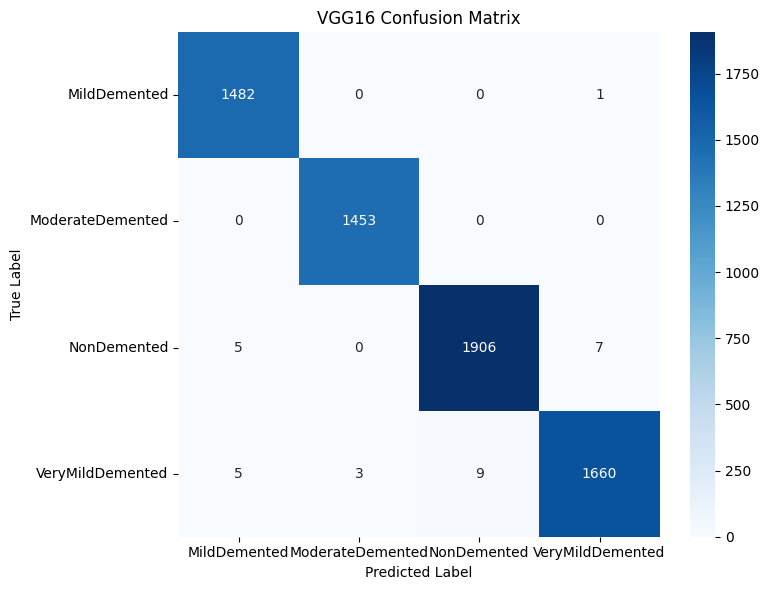

In [46]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import seaborn as sns
import matplotlib.pyplot as plt

# Load best model
model.load_state_dict(
    torch.load(
        MODEL_DIR / "best_model.pth",
        map_location=device
    )
)

model.eval()

y_true, y_pred = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())

# Evaluation
print("Test Accuracy:", accuracy_score(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=test_dataset.classes,
    digits=4
))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=test_dataset.classes,
    yticklabels=test_dataset.classes
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("VGG16 Confusion Matrix")
plt.tight_layout()
plt.show()

In [47]:
import copy

def new_layer(layer, g):
    layer = copy.deepcopy(layer)

    if hasattr(layer, "weight"):
        layer.weight = nn.Parameter(g(layer.weight))

    if hasattr(layer, "bias") and layer.bias is not None:
        layer.bias = nn.Parameter(g(layer.bias))

    return layer


def dense_to_conv(layers):
    new_layers = []

    for i, layer in enumerate(layers):
        if isinstance(layer, nn.Linear):

            if i == 0:
                m, n = 512, layer.weight.shape[0]
                new_layer_ = nn.Conv2d(m, n, 7)
                new_layer_.weight = nn.Parameter(
                    layer.weight.reshape(n, m, 7, 7)
                )
            else:
                m, n = layer.weight.shape[1], layer.weight.shape[0]
                new_layer_ = nn.Conv2d(m, n, 1)
                new_layer_.weight = nn.Parameter(
                    layer.weight.reshape(n, m, 1, 1)
                )

            new_layer_.bias = nn.Parameter(layer.bias)
            new_layers.append(new_layer_)

        else:
            new_layers.append(layer)

    return new_layers


def get_linear_layer_indices(model):
    offset = len(model.vgg16.features) + 1

    indices = [
        i for i, layer in enumerate(model.vgg16.classifier)
        if isinstance(layer, nn.Linear)
    ]

    return [offset + i for i in indices]


def apply_lrp_on_vgg16(model, image):

    model.eval()

    image = image.unsqueeze(0).to(device)

    layers = (
        list(model.vgg16.features)
        + [model.vgg16.avgpool]
        + dense_to_conv(list(model.vgg16.classifier))
    )

    linear_indices = get_linear_layer_indices(model)
    n_layers = len(layers)

    activations = [image] + [None] * n_layers

    # Forward propagation
    with torch.no_grad():
        for layer in range(n_layers):

            if layer in linear_indices and layer == linear_indices[0]:
                activations[layer] = activations[layer].reshape(
                    1, 512, 7, 7
                )

            activation = layers[layer](activations[layer])

            if isinstance(layers[layer], nn.AdaptiveAvgPool2d):
                activation = torch.flatten(activation, start_dim=1)

            activations[layer + 1] = activation

    # Select the predicted class
    output = activations[-1]
    predicted_class = output.argmax(dim=1).item()

    one_hot = torch.zeros_like(output)
    one_hot[0, predicted_class] = output[0, predicted_class]

    relevances = [None] * (n_layers + 1)
    relevances[-1] = one_hot.detach()

    # Backward relevance propagation
    for layer in reversed(range(n_layers)):

        current = layers[layer]

        if isinstance(current, nn.MaxPool2d):
            layers[layer] = nn.AvgPool2d(
                kernel_size=current.kernel_size,
                stride=current.stride,
                padding=current.padding
            )
            current = layers[layer]

        if isinstance(current, (nn.Conv2d, nn.AvgPool2d, nn.Linear)):

            activations[layer] = (
                activations[layer].detach().requires_grad_(True)
            )

            if layer <= 16:
                rho = lambda p: p + 0.25 * p.clamp(min=0)
                incr = lambda z: z + 1e-9

            elif 17 <= layer <= 30:
                rho = lambda p: p
                incr = lambda z: (
                    z + 1e-9 + 0.25 * (z.pow(2).mean().sqrt()).detach()
                )

            else:
                rho = lambda p: p
                incr = lambda z: z + 1e-9

            z = incr(
                new_layer(current, rho)(activations[layer])
            )

            s = (relevances[layer + 1] / z).detach()

            (z * s).sum().backward()

            c = activations[layer].grad
            relevances[layer] = (
                activations[layer] * c
            ).detach()

        else:
            relevances[layer] = relevances[layer + 1]

    return relevances[0], predicted_class

True label: MildDemented
Predicted label: MildDemented


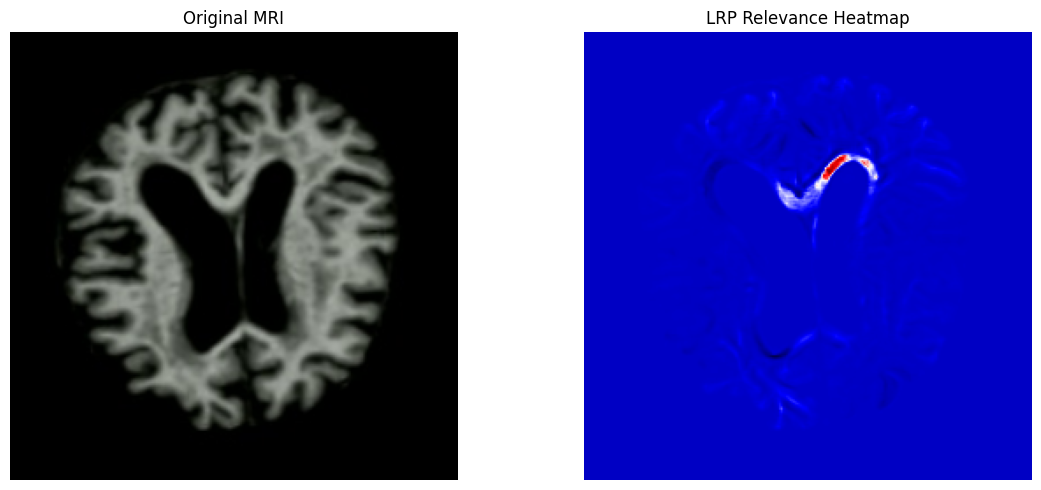

In [48]:
image_index = 0

image, true_label = test_dataset[image_index]

relevance, predicted_class = apply_lrp_on_vgg16(
    model, image
)

class_names = test_dataset.classes

print("True label:", class_names[true_label])
print("Predicted label:", class_names[predicted_class])

# Convert relevance to visualization format
relevance_map = relevance.sum(dim=1).squeeze().cpu().numpy()

# Normalize for visualization
relevance_map = (
    relevance_map - relevance_map.min()
) / (
    relevance_map.max() - relevance_map.min() + 1e-9
)

original_image = image.permute(1, 2, 0).numpy()

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(relevance_map, cmap="seismic")
plt.title("LRP Relevance Heatmap")
plt.axis("off")

plt.tight_layout()
plt.show()

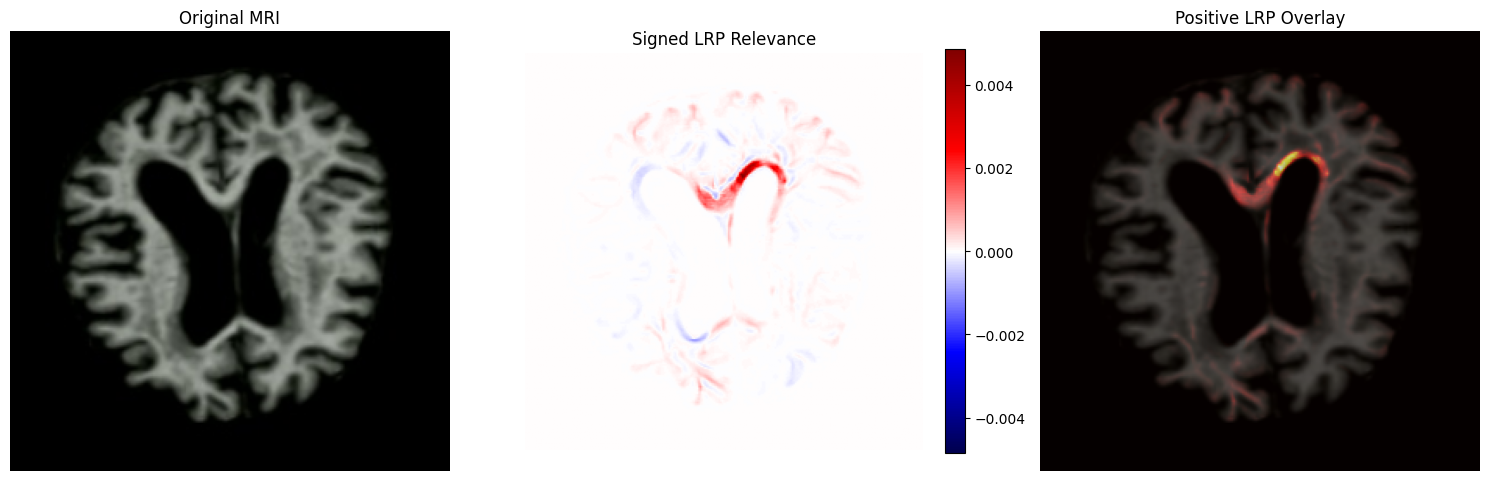

Relevance minimum: -0.0010037941
Relevance maximum: 0.0048625846
Total relevance: 1.4522445


In [49]:
import numpy as np
import matplotlib.pyplot as plt

# Convert relevance to 2D map
rel_map = relevance.sum(dim=1).squeeze().cpu().numpy()

# Symmetric normalization around zero
limit = np.max(np.abs(rel_map)) + 1e-9

plt.figure(figsize=(15, 5))

# Original MRI
plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title("Original MRI")
plt.axis("off")

# Positive and negative relevance
plt.subplot(1, 3, 2)
plt.imshow(rel_map, cmap="seismic",
           vmin=-limit, vmax=limit)
plt.colorbar(fraction=0.046)
plt.title("Signed LRP Relevance")
plt.axis("off")

# Positive relevance only
positive_map = np.maximum(rel_map, 0)

plt.subplot(1, 3, 3)
plt.imshow(original_image)
plt.imshow(positive_map, cmap="hot", alpha=0.55)
plt.title("Positive LRP Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Relevance minimum:", rel_map.min())
print("Relevance maximum:", rel_map.max())
print("Total relevance:", rel_map.sum())

In [55]:
target_layer = model.vgg16.features[28]

target_layer._backward_hooks.clear()
target_layer._forward_hooks.clear()

print("Old hooks cleared.")
print("Backward hooks:", len(target_layer._backward_hooks))
print("Forward hooks:", len(target_layer._forward_hooks))

Old hooks cleared.
Backward hooks: 0
Forward hooks: 0


In [56]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None

        self.handle = target_layer.register_forward_hook(
            self.forward_hook
        )

    def forward_hook(self, module, inputs, output):
        self.activations = output
        output.register_hook(self.save_gradient)

    def save_gradient(self, gradient):
        self.gradients = gradient

    def generate(self, image, class_idx=None):
        self.model.eval()
        self.model.zero_grad(set_to_none=True)

        self.activations = None
        self.gradients = None

        x = image.unsqueeze(0).to(device)
        output = self.model(x)

        if class_idx is None:
            class_idx = output.argmax(dim=1).item()

        output[0, class_idx].backward()

        weights = self.gradients.mean(
            dim=(2, 3), keepdim=True
        )

        cam = torch.relu(
            (weights * self.activations).sum(dim=1)
        )

        cam = torch.nn.functional.interpolate(
            cam.unsqueeze(1),
            size=(255, 255),
            mode="bilinear",
            align_corners=False
        )

        cam = cam[0, 0].detach().cpu().numpy()
        cam = cam / (cam.max() + 1e-9)

        return cam, class_idx

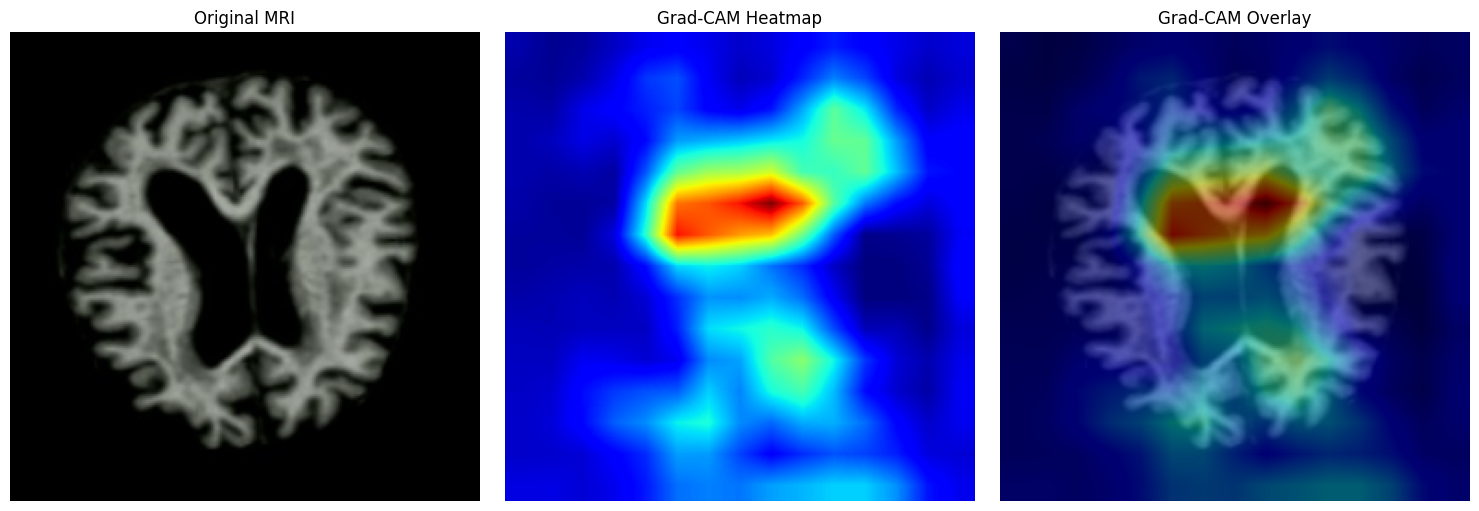

True label: MildDemented
Predicted label: MildDemented


In [57]:
gradcam = GradCAM(model, target_layer)

gradcam_map, predicted_class = gradcam.generate(image)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gradcam_map, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(original_image)
plt.imshow(gradcam_map, cmap="jet", alpha=0.45)
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

print("True label:", class_names[true_label])
print("Predicted label:", class_names[predicted_class])

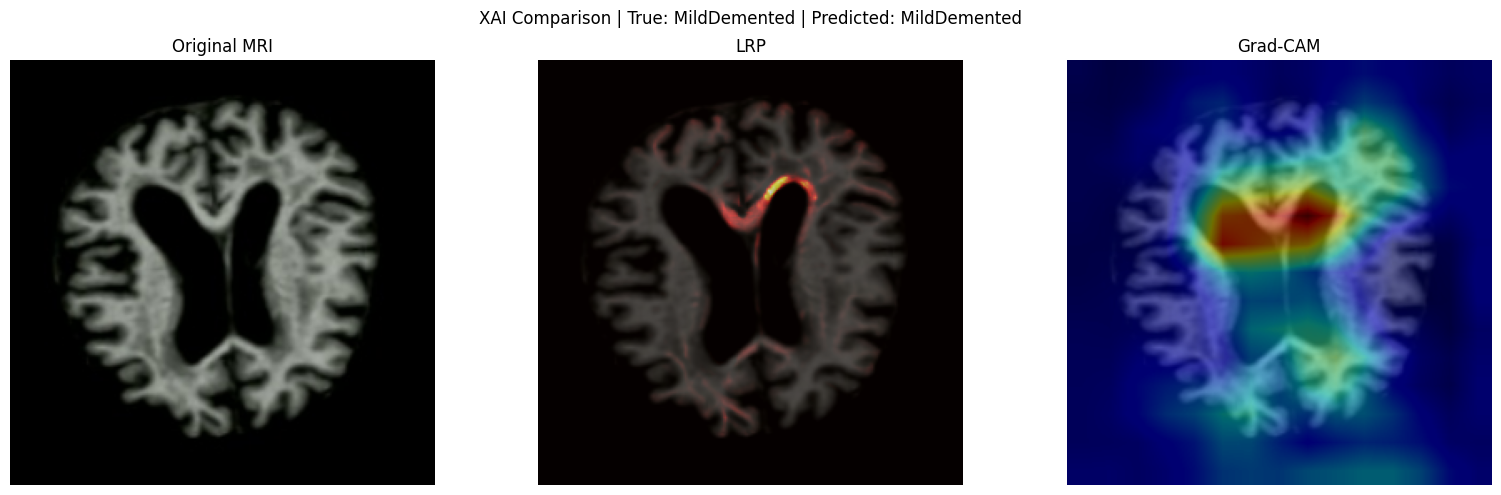

In [58]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Original MRI
axes[0].imshow(original_image)
axes[0].set_title("Original MRI")

# LRP
axes[1].imshow(original_image)
axes[1].imshow(
    np.maximum(rel_map, 0),
    cmap="hot",
    alpha=0.55
)
axes[1].set_title("LRP")

# Grad-CAM
axes[2].imshow(original_image)
axes[2].imshow(
    gradcam_map,
    cmap="jet",
    alpha=0.45
)
axes[2].set_title("Grad-CAM")

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"XAI Comparison | True: {class_names[true_label]} "
    f"| Predicted: {class_names[predicted_class]}"
)

plt.tight_layout()
plt.show()

In [61]:
# Temporarily remove Grad-CAM hook
gradcam.handle.remove()

selected_samples = {}

model.eval()

for idx, (img, label) in enumerate(test_dataset):

    if label in selected_samples:
        continue

    with torch.no_grad():
        prediction = model(img.unsqueeze(0).to(device))
        pred_label = prediction.argmax(1).item()

    if pred_label == label:
        selected_samples[label] = (img, label)

    if len(selected_samples) == 4:
        break

# Register Grad-CAM again
gradcam = GradCAM(model, target_layer)

print("Selected samples:")

for label, (img, _) in selected_samples.items():
    print(class_names[label])

Selected samples:
MildDemented
ModerateDemented
NonDemented
VeryMildDemented


MildDemented | LRP prediction: MildDemented | Grad-CAM target: MildDemented
ModerateDemented | LRP prediction: ModerateDemented | Grad-CAM target: ModerateDemented
NonDemented | LRP prediction: NonDemented | Grad-CAM target: NonDemented
VeryMildDemented | LRP prediction: VeryMildDemented | Grad-CAM target: VeryMildDemented


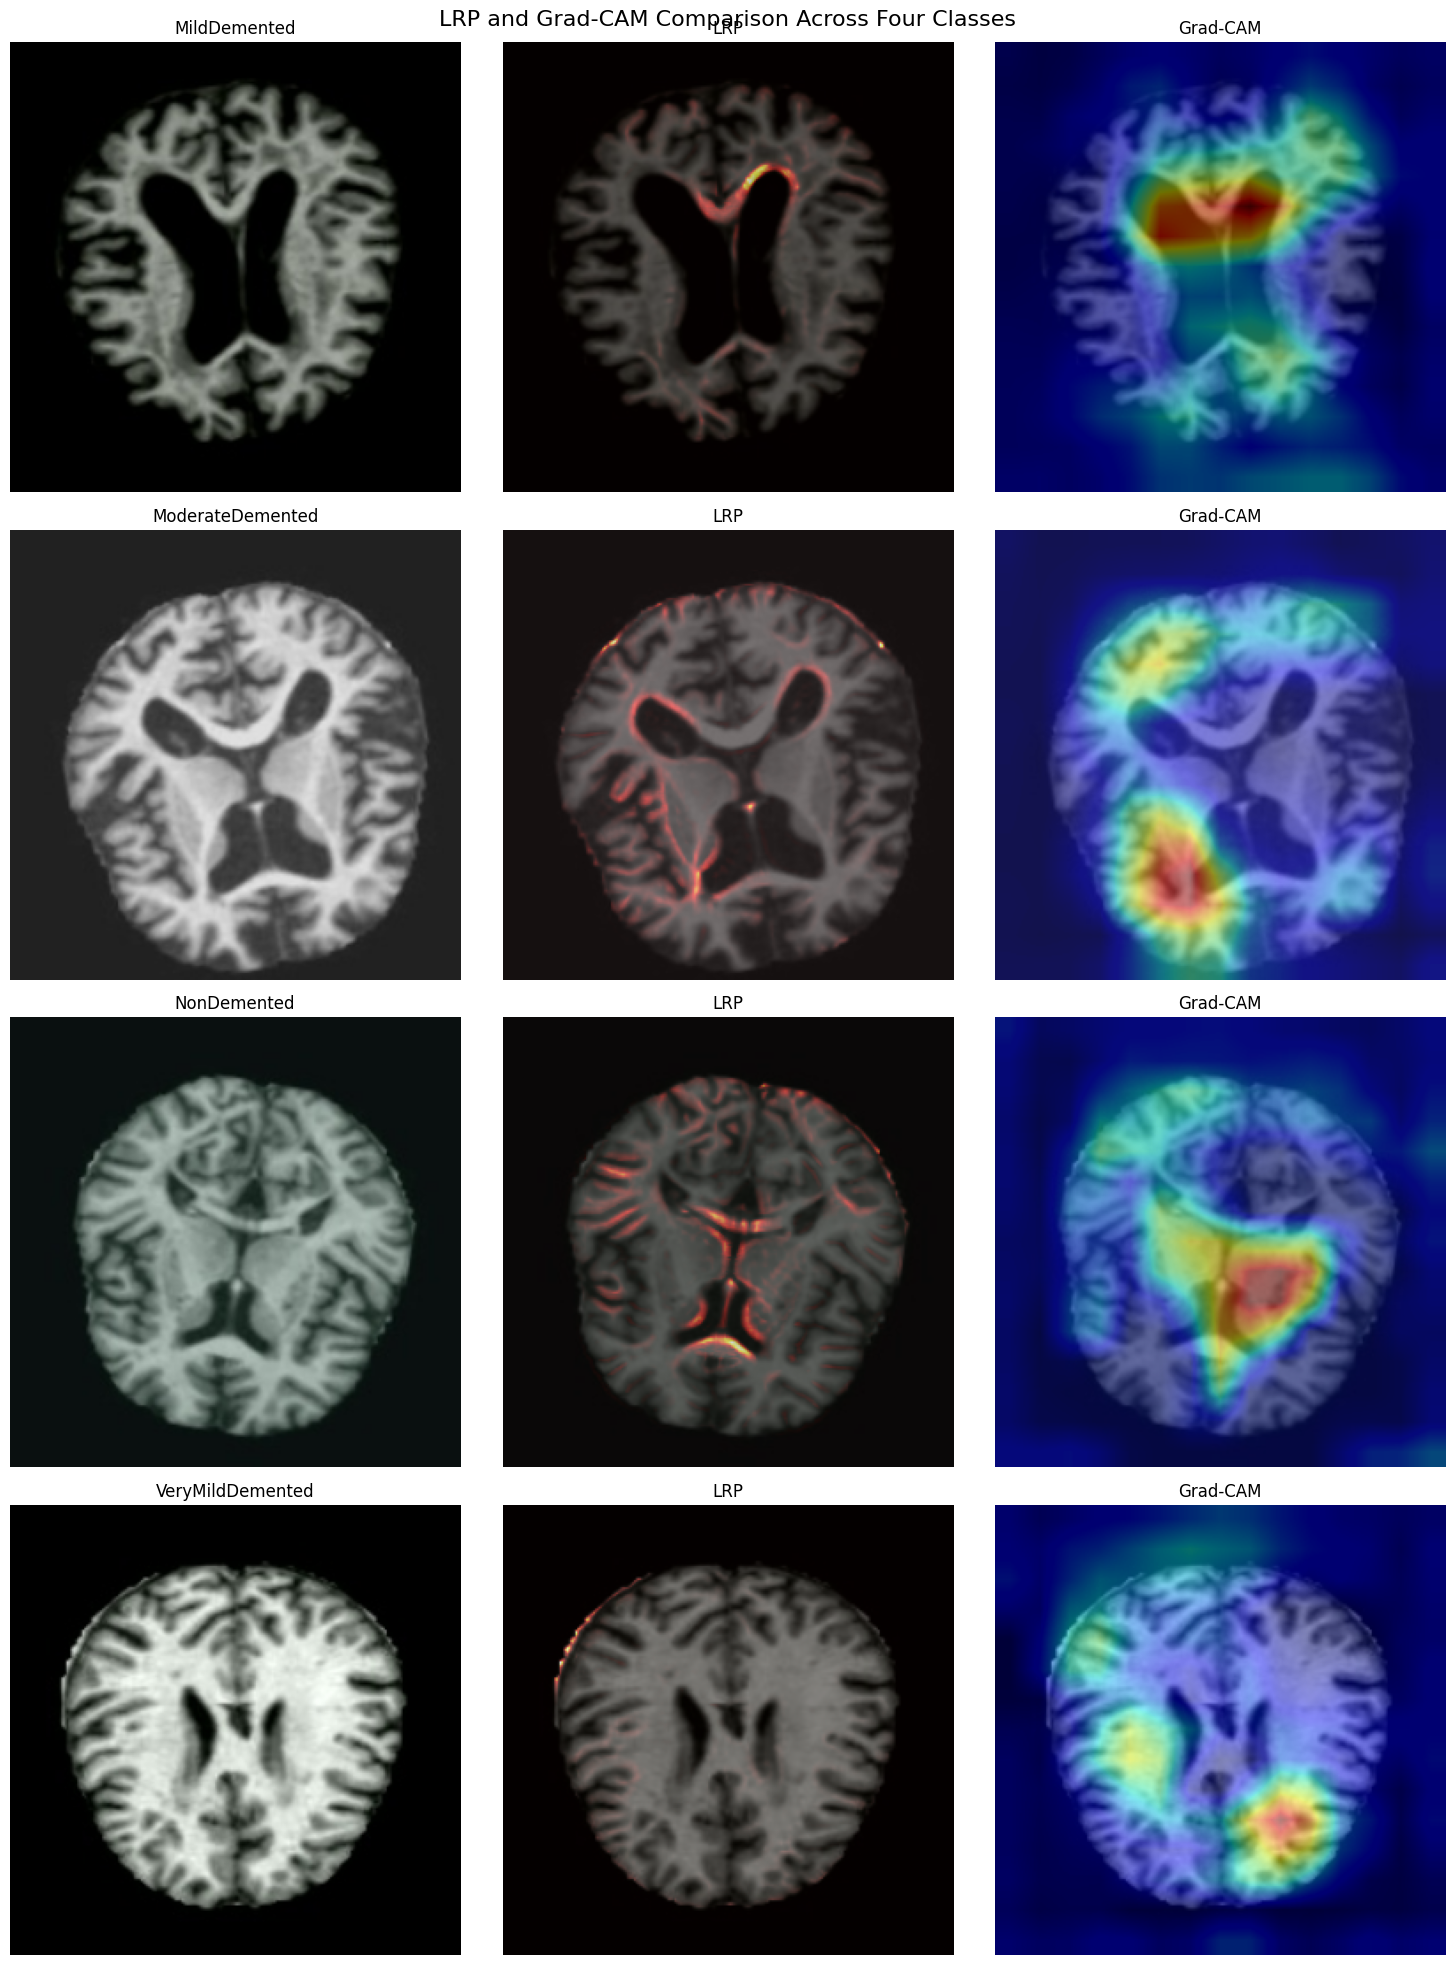

In [63]:
fig, axes = plt.subplots(4, 3, figsize=(15, 20))

# Remove existing Grad-CAM hook before LRP
if hasattr(gradcam, "handle"):
    gradcam.handle.remove()

for row, (label, (img, true_label)) in enumerate(
    selected_samples.items()
):

    # 1. Generate LRP first
    relevance, lrp_pred = apply_lrp_on_vgg16(model, img)

    rel_map = relevance.sum(dim=1).squeeze().cpu().numpy()
    positive_rel = np.maximum(rel_map, 0)

    positive_rel = positive_rel / (
        positive_rel.max() + 1e-9
    )

    # 2. Create Grad-CAM only after LRP
    current_gradcam = GradCAM(model, target_layer)

    gradcam_map, gradcam_pred = current_gradcam.generate(
        img, class_idx=lrp_pred
    )

    # Remove hook immediately after Grad-CAM
    current_gradcam.handle.remove()

    # Original MRI
    original = img.permute(1, 2, 0).numpy()

    axes[row, 0].imshow(original)
    axes[row, 0].set_title(class_names[true_label])

    # LRP
    axes[row, 1].imshow(original)
    axes[row, 1].imshow(
        positive_rel, cmap="hot", alpha=0.5
    )
    axes[row, 1].set_title("LRP")

    # Grad-CAM
    axes[row, 2].imshow(original)
    axes[row, 2].imshow(
        gradcam_map, cmap="jet", alpha=0.45
    )
    axes[row, 2].set_title("Grad-CAM")

    print(
        f"{class_names[true_label]} | "
        f"LRP prediction: {class_names[lrp_pred]} | "
        f"Grad-CAM target: {class_names[gradcam_pred]}"
    )

for ax in axes.flat:
    ax.axis("off")

plt.suptitle(
    "LRP and Grad-CAM Comparison Across Four Classes",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [64]:
import torch.nn.functional as F
import pandas as pd

def evaluate_occlusion(model, image, saliency_map, class_idx, ratio=0.2):
    model.eval()

    x = image.unsqueeze(0).to(device)

    with torch.no_grad():
        original_prob = F.softmax(model(x), dim=1)[0, class_idx].item()

    # Select top 20% salient pixels
    saliency = torch.tensor(
        saliency_map, device=device
    )

    threshold = torch.quantile(
        saliency.flatten(), 1 - ratio
    )

    mask = (saliency >= threshold).float()

    # Replace selected pixels with zero
    masked_image = x * (1 - mask.unsqueeze(0).unsqueeze(0))

    with torch.no_grad():
        masked_prob = F.softmax(
            model(masked_image), dim=1
        )[0, class_idx].item()

    return original_prob, masked_prob, original_prob - masked_prob


results = []

for label, (img, true_label) in selected_samples.items():

    # Generate LRP
    relevance, pred = apply_lrp_on_vgg16(model, img)
    lrp_map = relevance.sum(dim=1).squeeze().cpu().numpy()
    lrp_map = np.maximum(lrp_map, 0)

    # Generate Grad-CAM
    current_gradcam = GradCAM(model, target_layer)
    cam_map, _ = current_gradcam.generate(img, class_idx=pred)
    current_gradcam.handle.remove()

    # Evaluate both explanations
    for method, saliency in [
        ("LRP", lrp_map),
        ("Grad-CAM", cam_map)
    ]:
        original, masked, drop = evaluate_occlusion(
            model, img, saliency, pred
        )

        results.append({
            "Class": class_names[true_label],
            "Method": method,
            "Original Probability": original,
            "Masked Probability": masked,
            "Probability Drop": drop
        })

occlusion_df = pd.DataFrame(results)

display(occlusion_df.round(4))

,Class,Method,Original Probability,Masked Probability,Probability Drop
0,MildDemented,LRP,1.0000,0.7067,0.2933
1,MildDemented,Grad-CAM,1.0000,0.9989,0.0011
2,ModerateDemented,LRP,1.0000,1.0000,0.0000
3,ModerateDemented,Grad-CAM,1.0000,0.0461,0.9539
4,NonDemented,LRP,0.9984,0.5257,0.4727
5,NonDemented,Grad-CAM,0.9984,0.0373,0.9611
6,VeryMildDemented,LRP,0.9996,0.0000,0.9996
7,VeryMildDemented,Grad-CAM,0.9996,0.9999,-0.0003


In [65]:
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

def occlusion_test(model, image, saliency_map, class_idx,
                   ratio=0.2, random_seed=42):

    model.eval()
    x = image.unsqueeze(0).to(device)

    # Original probability
    with torch.no_grad():
        original_prob = F.softmax(model(x), dim=1)[0, class_idx].item()

    h, w = saliency_map.shape
    total_pixels = h * w
    k = int(total_pixels * ratio)

    # Exact Top-K mask
    flat = np.asarray(saliency_map).flatten()
    top_indices = np.argpartition(flat, -k)[-k:]

    mask = np.zeros(total_pixels, dtype=bool)
    mask[top_indices] = True
    mask = torch.tensor(mask.reshape(h, w), device=device)

    # Random mask with exactly the same number of pixels
    rng = np.random.default_rng(random_seed)
    random_indices = rng.choice(total_pixels, k, replace=False)

    random_mask = np.zeros(total_pixels, dtype=bool)
    random_mask[random_indices] = True
    random_mask = torch.tensor(
        random_mask.reshape(h, w), device=device
    )

    # Fill with per-channel image mean
    fill = x.mean(dim=(2, 3), keepdim=True)

    def predict_masked(pixel_mask):
        pixel_mask = pixel_mask.unsqueeze(0).unsqueeze(0)
        masked = torch.where(pixel_mask, fill, x)

        with torch.no_grad():
            prob = F.softmax(model(masked), dim=1)[0, class_idx].item()

        return prob

    salient_prob = predict_masked(mask)
    random_prob = predict_masked(random_mask)

    return {
        "Original": original_prob,
        "Saliency Masked": salient_prob,
        "Saliency Drop": original_prob - salient_prob,
        "Random Masked": random_prob,
        "Random Drop": original_prob - random_prob,
        "Mask Ratio": mask.float().mean().item()
    }


# Evaluate all four classes
results = []

for label, (img, true_label) in selected_samples.items():

    # LRP
    relevance, pred = apply_lrp_on_vgg16(model, img)
    lrp_map = relevance.sum(dim=1).squeeze().cpu().numpy()
    lrp_map = np.maximum(lrp_map, 0)

    # Grad-CAM
    current_gradcam = GradCAM(model, target_layer)
    cam_map, _ = current_gradcam.generate(img, class_idx=pred)
    current_gradcam.handle.remove()

    for method, saliency in [
        ("LRP", lrp_map),
        ("Grad-CAM", cam_map)
    ]:
        result = occlusion_test(
            model, img, saliency, pred
        )

        results.append({
            "Class": class_names[true_label],
            "Method": method,
            **result
        })

occlusion_df = pd.DataFrame(results)

display(occlusion_df.round(4))

,Class,Method,Original,Saliency Masked,Saliency Drop,Random Masked,Random Drop,Mask Ratio
0,MildDemented,LRP,1.0000,1.0000,0.0000,0.0729,0.9271,0.2
1,MildDemented,Grad-CAM,1.0000,0.9983,0.0017,0.0729,0.9271,0.2
2,ModerateDemented,LRP,1.0000,0.0106,0.9894,0.0307,0.9693,0.2
3,ModerateDemented,Grad-CAM,1.0000,0.0064,0.9936,0.0307,0.9693,0.2
4,NonDemented,LRP,0.9984,0.0000,0.9984,0.9970,0.0015,0.2
5,NonDemented,Grad-CAM,0.9984,0.0019,0.9965,0.9970,0.0015,0.2
6,VeryMildDemented,LRP,0.9996,0.0000,0.9996,0.6662,0.3334,0.2
7,VeryMildDemented,Grad-CAM,0.9996,0.9997,-0.0001,0.6662,0.3334,0.2


In [66]:
import os

RESULT_DIR = "/content/alzheimer_processed/xai_results"
os.makedirs(RESULT_DIR, exist_ok=True)

# Save quantitative results
occlusion_df.to_csv(
    f"{RESULT_DIR}/occlusion_results.csv",
    index=False
)

# Save four-class XAI comparison figure
plt.savefig(
    f"{RESULT_DIR}/xai_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

print("XAI results saved successfully.")
print("Directory:", RESULT_DIR)

XAI results saved successfully.
Directory: /content/alzheimer_processed/xai_results


<Figure size 640x480 with 0 Axes>

In [67]:
from collections import defaultdict

samples_per_class = 10
multi_samples = defaultdict(list)

model.eval()

for idx, (img, label) in enumerate(test_dataset):

    if len(multi_samples[label]) >= samples_per_class:
        continue

    with torch.no_grad():
        output = model(img.unsqueeze(0).to(device))
        pred = output.argmax(dim=1).item()

    if pred == label:
        multi_samples[label].append((idx, img, label))

    if all(
        len(multi_samples[i]) >= samples_per_class
        for i in range(len(class_names))
    ):
        break

print("Selected samples:")

for label in range(len(class_names)):
    print(
        class_names[label],
        ":",
        len(multi_samples[label])
    )

Selected samples:
MildDemented : 10
ModerateDemented : 10
NonDemented : 10
VeryMildDemented : 10


In [68]:
multi_results = []

for label in range(len(class_names)):

    print(f"Evaluating: {class_names[label]}")

    for idx, img, true_label in multi_samples[label]:

        # LRP
        relevance, pred = apply_lrp_on_vgg16(model, img)

        lrp_map = relevance.sum(dim=1).squeeze().cpu().numpy()
        lrp_map = np.maximum(lrp_map, 0)

        # Grad-CAM
        current_gradcam = GradCAM(model, target_layer)
        cam_map, _ = current_gradcam.generate(
            img, class_idx=pred
        )
        current_gradcam.handle.remove()

        # Evaluate both methods
        for method, saliency in [
            ("LRP", lrp_map),
            ("Grad-CAM", cam_map)
        ]:

            result = occlusion_test(
                model,
                img,
                saliency,
                pred,
                ratio=0.2,
                random_seed=idx
            )

            multi_results.append({
                "Image_ID": idx,
                "Class": class_names[true_label],
                "Method": method,
                "Original": result["Original"],
                "Saliency_Drop": result["Saliency Drop"],
                "Random_Drop": result["Random Drop"],
                "Saliency_Advantage": (
                    result["Saliency Drop"]
                    - result["Random Drop"]
                )
            })

multi_df = pd.DataFrame(multi_results)

print("Evaluation completed.")
print("Total evaluations:", len(multi_df))

Evaluating: MildDemented
Evaluating: ModerateDemented
Evaluating: NonDemented
Evaluating: VeryMildDemented
Evaluation completed.
Total evaluations: 80


In [69]:
summary_df = (
    multi_df
    .groupby(["Class", "Method"])
    [["Saliency_Drop", "Random_Drop", "Saliency_Advantage"]]
    .agg(["mean", "std"])
    .round(4)
)

display(summary_df)

Saliency_Drop         Random_Drop          \
                                   mean     std        mean     std   
Class            Method                                               
MildDemented     Grad-CAM        0.5640  0.4148      0.9231  0.1908   
                 LRP             0.5646  0.4645      0.9231  0.1908   
ModerateDemented Grad-CAM        0.9492  0.1232      0.9894  0.0271   
                 LRP             0.9044  0.2443      0.9894  0.0271   
NonDemented      Grad-CAM        0.4736  0.4764      0.0064  0.0111   
                 LRP             0.7524  0.3749      0.0064  0.0111   
VeryMildDemented Grad-CAM        0.7800  0.3824      0.6924  0.3886   
                 LRP             0.6952  0.4342      0.6924  0.3886   

                          Saliency_Advantage          
                                        mean     std  
Class            Method                               
MildDemented     Grad-CAM            -0.3591  0.4955  
                 LRP                 -0.3585  0.3951  
ModerateDemented Grad-CAM            -0.0403  0.1290  
                 LRP                 -0.0850  0.2500  
NonDemented      Grad-CAM             0.4672  0.4785  
                 LRP                  0.7460  0.3726  
VeryMildDemented Grad-CAM             0.0877  0.5039  
                 LRP                  0.0028  0.6853

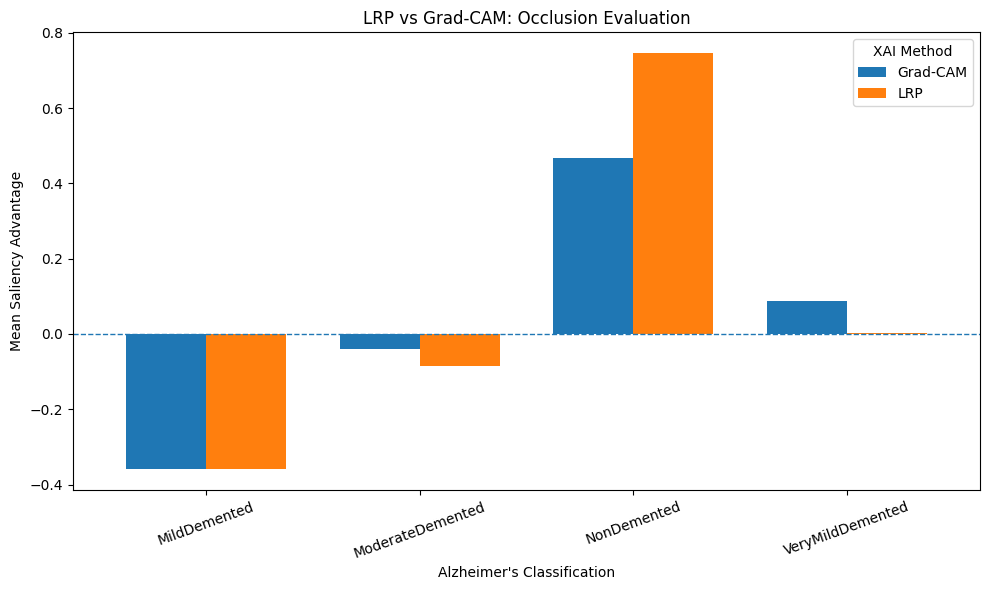

In [70]:
plot_df = (
    multi_df.groupby(["Class", "Method"])
    ["Saliency_Advantage"]
    .mean()
    .unstack()
)

plot_df = plot_df.reindex(class_names)

plot_df.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

plt.axhline(0, linestyle="--", linewidth=1)
plt.ylabel("Mean Saliency Advantage")
plt.xlabel("Alzheimer's Classification")
plt.title("LRP vs Grad-CAM: Occlusion Evaluation")
plt.xticks(rotation=20)
plt.legend(title="XAI Method")
plt.tight_layout()
plt.show()

In [71]:
import os

RESULT_DIR = "/content/alzheimer_processed/xai_results"
os.makedirs(RESULT_DIR, exist_ok=True)

multi_df.to_csv(
    f"{RESULT_DIR}/multi_sample_results.csv",
    index=False
)

summary_df.to_csv(
    f"{RESULT_DIR}/xai_statistical_summary.csv"
)

print("Results saved:")
print(RESULT_DIR)

Results saved:
/content/alzheimer_processed/xai_results


In [72]:
from sklearn.metrics import confusion_matrix
import pandas as pd
import numpy as np

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(class_names))
)

error_results = []

for i, class_name in enumerate(class_names):

    TP = cm[i, i]
    FN = cm[i, :].sum() - TP
    FP = cm[:, i].sum() - TP
    TN = cm.sum() - TP - FN - FP

    error_results.append({
        "Class": class_name,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "TN": TN
    })

error_df = pd.DataFrame(error_results)

display(error_df)

,Class,TP,FP,FN,TN
0,MildDemented,1482,10,1,5038
1,ModerateDemented,1453,3,0,5075
2,NonDemented,1906,9,12,4604
3,VeryMildDemented,1660,8,17,4846


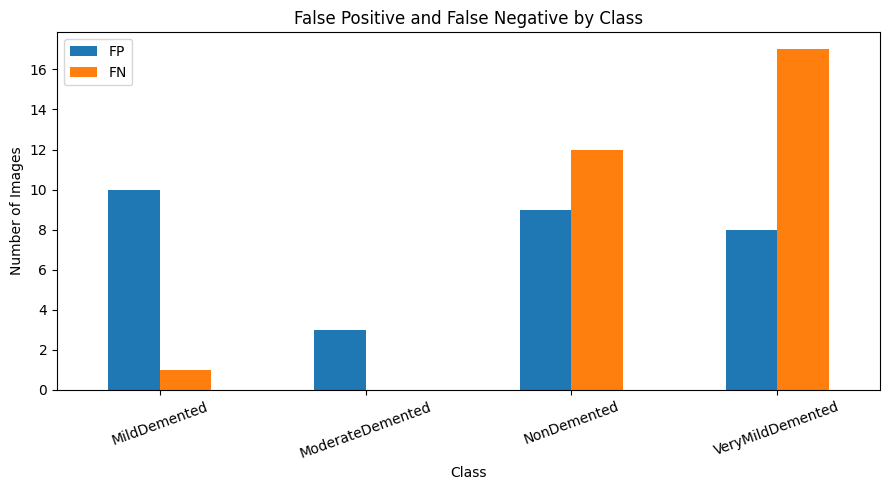

In [73]:
error_df.set_index("Class")[["FP", "FN"]].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("False Positive and False Negative by Class")
plt.ylabel("Number of Images")
plt.xlabel("Class")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Total misclassified images: 30


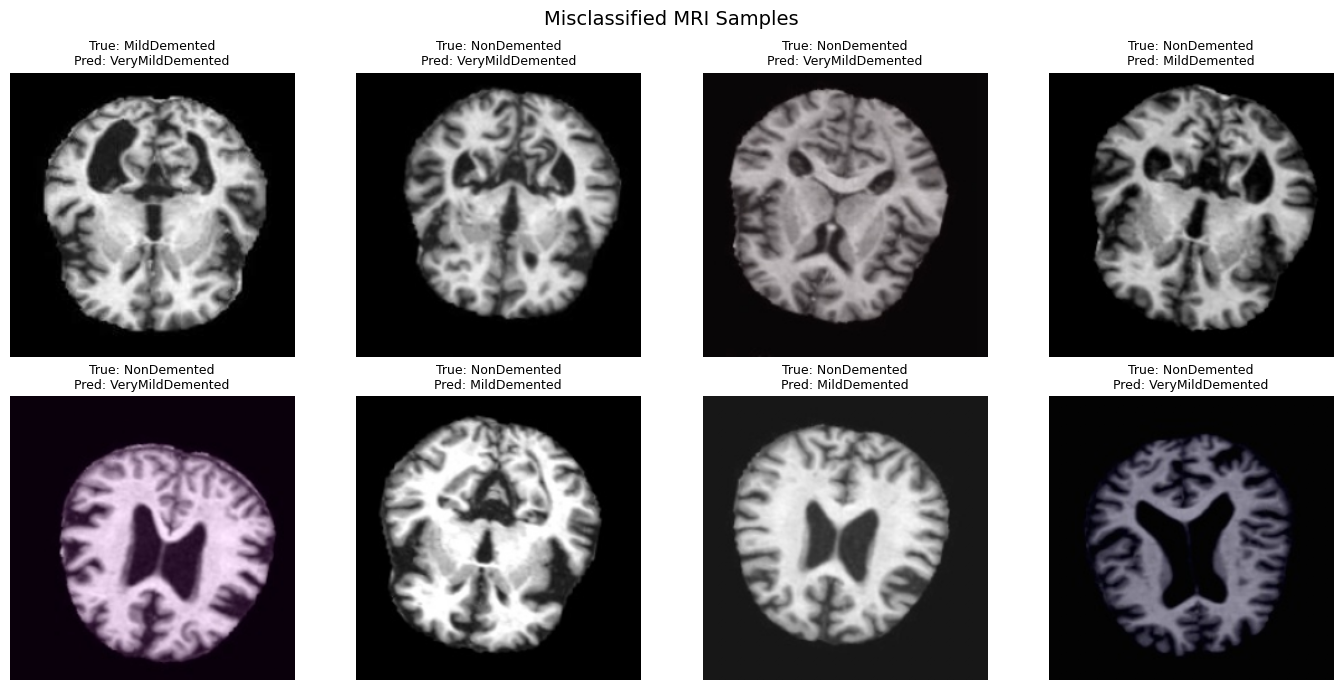

In [74]:
import matplotlib.pyplot as plt
import torch

wrong_indices = [
    i for i, (true, pred) in enumerate(zip(y_true, y_pred))
    if true != pred
]

print("Total misclassified images:", len(wrong_indices))

# Display up to 8 misclassified samples
num_show = min(8, len(wrong_indices))

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()

for i, idx in enumerate(wrong_indices[:num_show]):

    img, true_label = test_dataset[idx]

    with torch.no_grad():
        output = model(img.unsqueeze(0).to(device))
        pred_label = output.argmax(dim=1).item()

    image = img.cpu().permute(1, 2, 0).numpy()
    image = image.clip(0, 1)

    axes[i].imshow(image)
    axes[i].set_title(
        f"True: {class_names[true_label]}\n"
        f"Pred: {class_names[pred_label]}",
        fontsize=9
    )
    axes[i].axis("off")

for i in range(num_show, len(axes)):
    axes[i].axis("off")

plt.suptitle("Misclassified MRI Samples", fontsize=14)
plt.tight_layout()
plt.show()

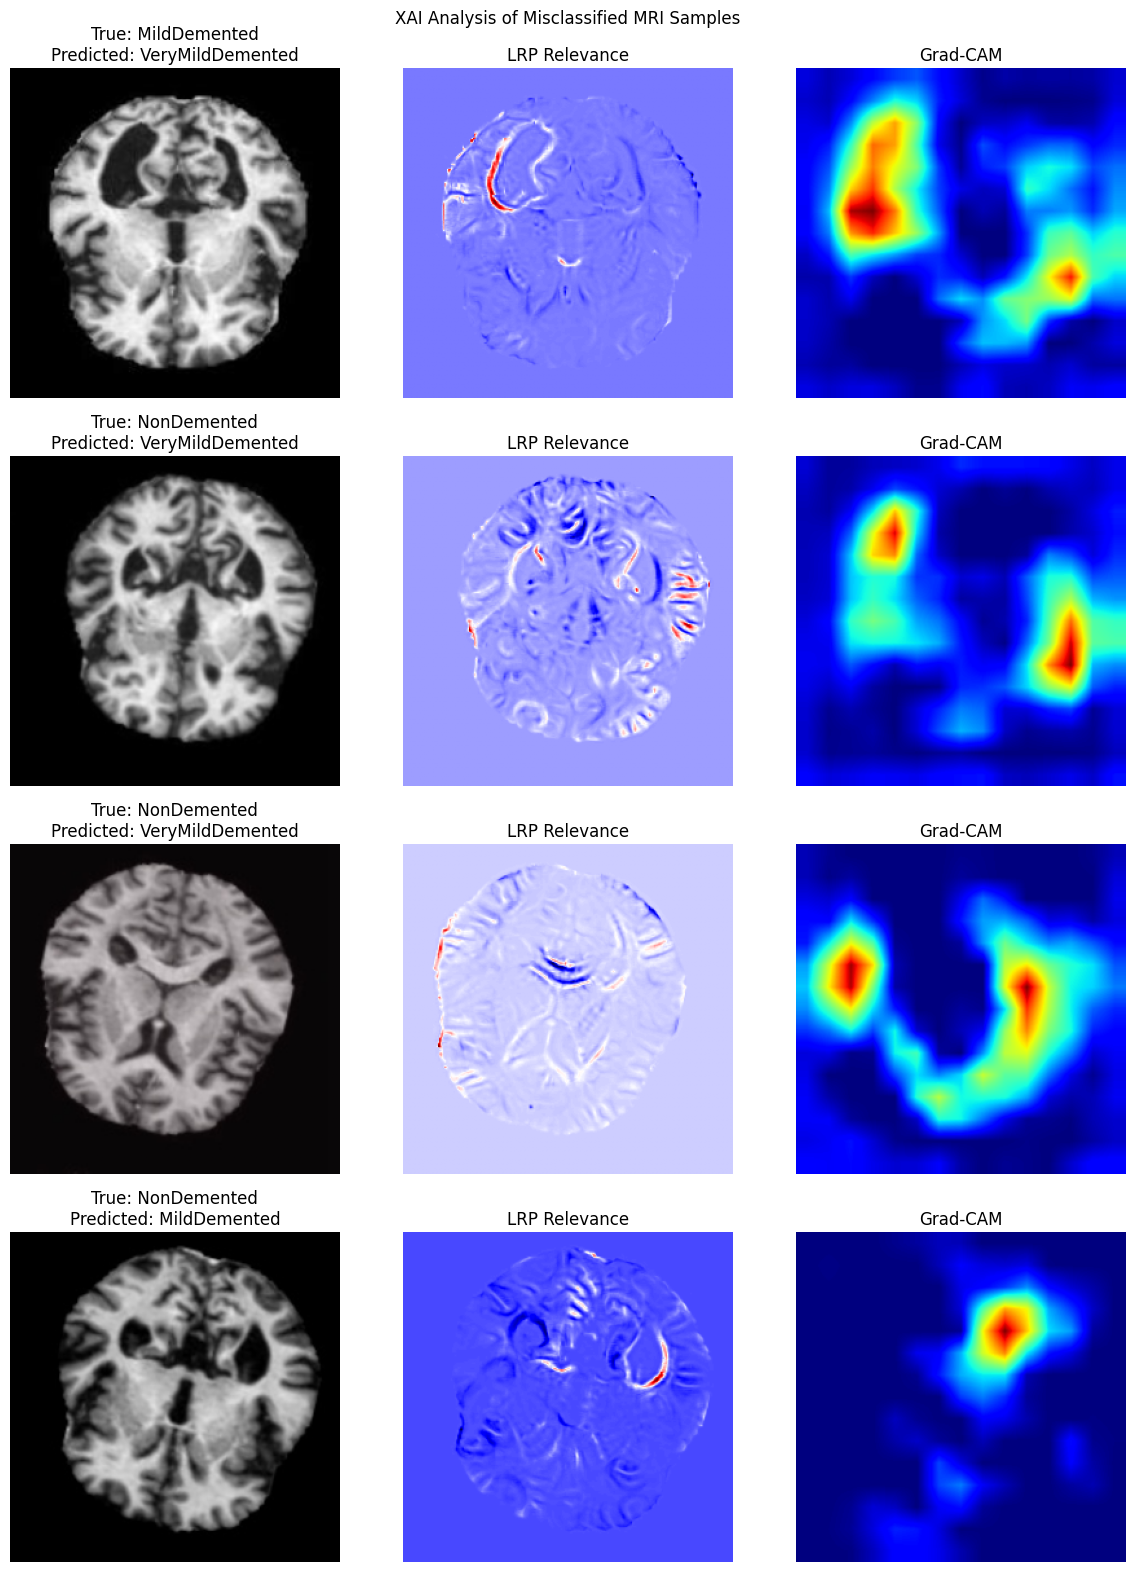

In [75]:
fig, axes = plt.subplots(4, 3, figsize=(12, 16))

for row, idx in enumerate(wrong_indices[:4]):

    img, true_label = test_dataset[idx]
    img = img.to(device)

    # Model prediction
    with torch.no_grad():
        output = model(img.unsqueeze(0))
        pred = output.argmax(dim=1).item()

    # LRP
    relevance, _ = apply_lrp_on_vgg16(model, img)
    lrp_map = relevance.sum(dim=1).squeeze().detach().cpu().numpy()

    # Grad-CAM
    current_gradcam = GradCAM(model, target_layer)
    cam_map, _ = current_gradcam.generate(
        img, class_idx=pred
    )
    current_gradcam.handle.remove()

    # Original image
    original = img.detach().cpu().permute(1, 2, 0).numpy()
    original = np.clip(original, 0, 1)

    axes[row, 0].imshow(original)
    axes[row, 0].set_title(
        f"True: {class_names[true_label]}\n"
        f"Predicted: {class_names[pred]}"
    )

    axes[row, 1].imshow(lrp_map, cmap="seismic")
    axes[row, 1].set_title("LRP Relevance")

    axes[row, 2].imshow(cam_map, cmap="jet")
    axes[row, 2].set_title("Grad-CAM")

    for ax in axes[row]:
        ax.axis("off")

plt.suptitle("XAI Analysis of Misclassified MRI Samples")
plt.tight_layout()
plt.show()

In [76]:
error_pairs = pd.DataFrame({
    "True": [
        class_names[y_true[i]] for i in wrong_indices
    ],
    "Predicted": [
        class_names[y_pred[i]] for i in wrong_indices
    ]
})

error_summary = (
    error_pairs
    .value_counts()
    .reset_index(name="Count")
)

display(error_summary)

error_summary.to_csv(
    "/content/alzheimer_processed/xai_results/error_patterns.csv",
    index=False
)

print("Error pattern analysis saved.")

,True,Predicted,Count
0,VeryMildDemented,NonDemented,9
1,NonDemented,VeryMildDemented,7
2,VeryMildDemented,MildDemented,5
3,NonDemented,MildDemented,5
4,VeryMildDemented,ModerateDemented,3
5,MildDemented,VeryMildDemented,1


Error pattern analysis saved.


In [77]:
import os
import torch
import json

FINAL_DIR = "/content/alzheimer_processed/final_results"
os.makedirs(FINAL_DIR, exist_ok=True)

# Save trained model
torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": class_names,
    "model_name": "VGG16"
}, f"{FINAL_DIR}/vgg16_model.pth")

# Save classification results
error_df.to_csv(
    f"{FINAL_DIR}/classification_errors.csv",
    index=False
)

error_summary.to_csv(
    f"{FINAL_DIR}/error_patterns.csv",
    index=False
)

multi_df.to_csv(
    f"{FINAL_DIR}/multi_sample_xai_results.csv",
    index=False
)

# Save statistical summary
summary_df.to_csv(
    f"{FINAL_DIR}/xai_statistical_summary.csv"
)

# Save confusion matrix
pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
).to_csv(f"{FINAL_DIR}/confusion_matrix.csv")

print("Final experiment package saved.")
print("Location:", FINAL_DIR)
print("Files:", os.listdir(FINAL_DIR))

Final experiment package saved.
Location: /content/alzheimer_processed/final_results
Files: ['xai_statistical_summary.csv', 'classification_errors.csv', 'multi_sample_xai_results.csv', 'error_patterns.csv', 'confusion_matrix.csv', 'vgg16_model.pth']


In [78]:
import os

FINAL_DIR = "/content/alzheimer_processed/final_results"

for root, dirs, files in os.walk(FINAL_DIR):
    for file in files:
        path = os.path.join(root, file)
        print(file, "|", round(os.path.getsize(path) / 1024, 2), "KB")

xai_statistical_summary.csv | 0.63 KB
classification_errors.csv | 0.13 KB
multi_sample_xai_results.csv | 7.68 KB
error_patterns.csv | 0.21 KB
confusion_matrix.csv | 0.16 KB
vgg16_model.pth | 524531.78 KB


In [79]:
import os
import matplotlib.pyplot as plt

FIG_DIR = "/content/alzheimer_processed/final_results/figures"
os.makedirs(FIG_DIR, exist_ok=True)

# Save all currently available figures
for i, fig_num in enumerate(plt.get_fignums()):
    fig = plt.figure(fig_num)
    fig.savefig(
        f"{FIG_DIR}/figure_{i+1}.png",
        dpi=300,
        bbox_inches="tight"
    )

print("Figures saved:", len(plt.get_fignums()))
print("Location:", FIG_DIR)

Figures saved: 0
Location: /content/alzheimer_processed/final_results/figures


In [80]:
import os

BASE_DIR = "/content/alzheimer_processed/final_results"

for root, dirs, files in os.walk(BASE_DIR):
    print(f"\n[{root}]")
    for file in files:
        path = os.path.join(root, file)
        size_mb = os.path.getsize(path) / (1024 ** 2)
        print(f"{file} - {size_mb:.2f} MB")


[/content/alzheimer_processed/final_results]
xai_statistical_summary.csv - 0.00 MB
classification_errors.csv - 0.00 MB
multi_sample_xai_results.csv - 0.01 MB
error_patterns.csv - 0.00 MB
confusion_matrix.csv - 0.00 MB
vgg16_model.pth - 512.24 MB

[/content/alzheimer_processed/final_results/figures]


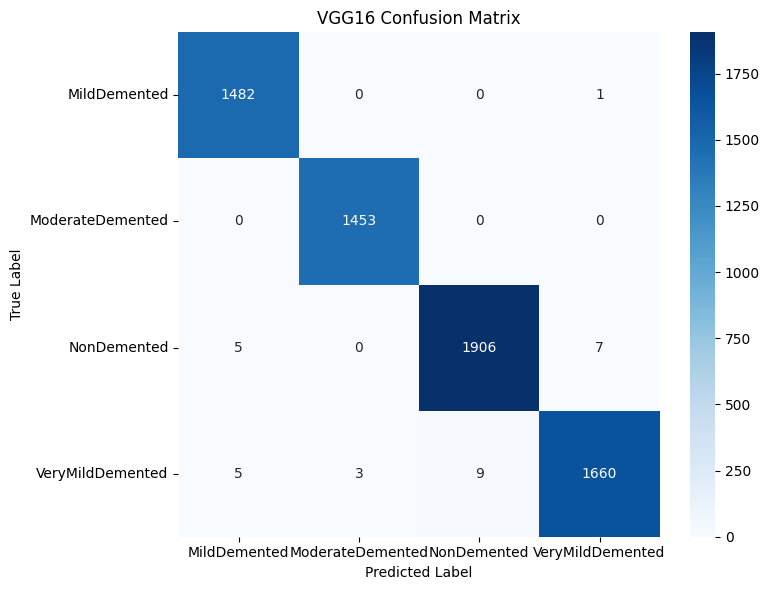

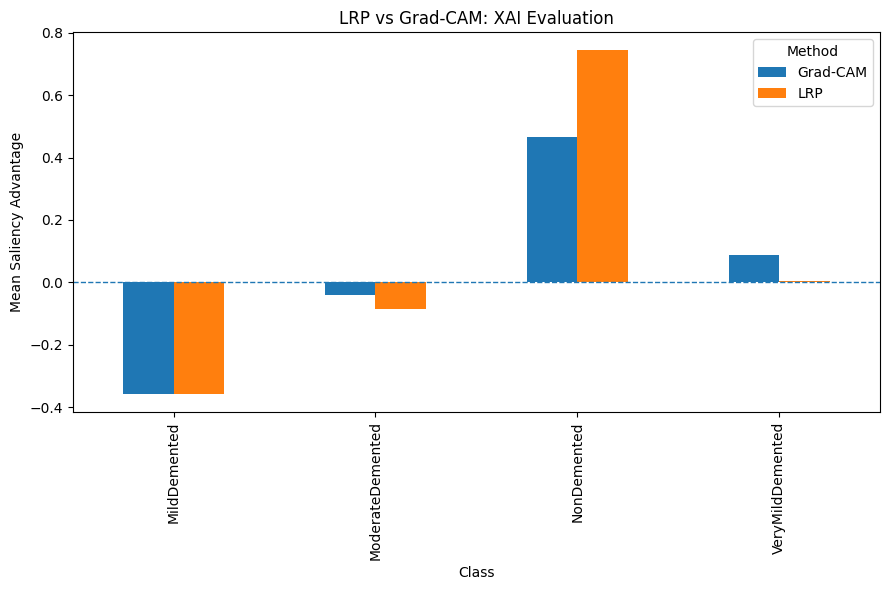

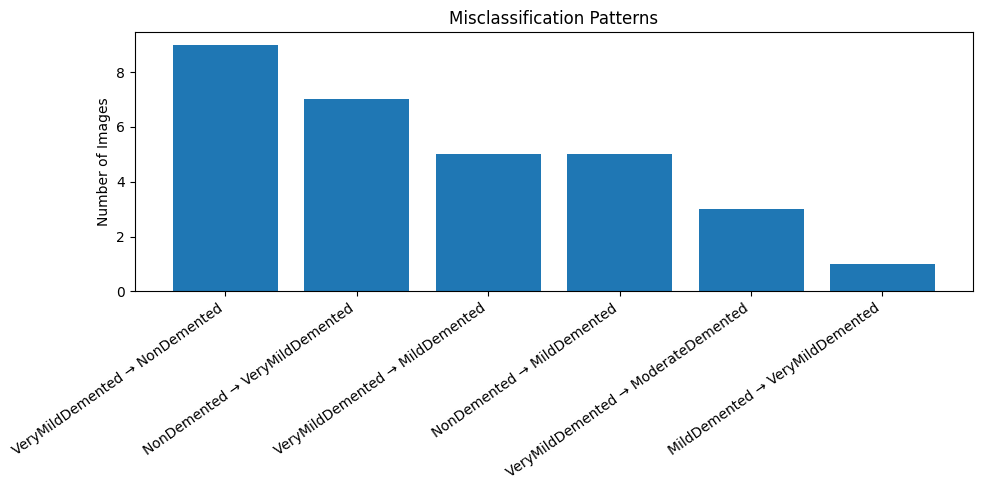

Figures generated:
['confusion_matrix.png', 'error_patterns.png', 'xai_comparison.png']


In [81]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BASE_DIR = "/content/alzheimer_processed/final_results"
FIG_DIR = os.path.join(BASE_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

# 1. Confusion Matrix
cm_df = pd.read_csv(
    f"{BASE_DIR}/confusion_matrix.csv",
    index_col=0
)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues")
plt.title("VGG16 Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/confusion_matrix.png", dpi=300)
plt.show()

# 2. LRP vs Grad-CAM
multi_df = pd.read_csv(
    f"{BASE_DIR}/multi_sample_xai_results.csv"
)

plot_df = multi_df.groupby(
    ["Class", "Method"]
)["Saliency_Advantage"].mean().unstack()

plot_df = plot_df.reindex(class_names)

plot_df.plot(kind="bar", figsize=(9, 6))
plt.axhline(0, linestyle="--", linewidth=1)
plt.title("LRP vs Grad-CAM: XAI Evaluation")
plt.ylabel("Mean Saliency Advantage")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/xai_comparison.png", dpi=300)
plt.show()

# 3. Misclassification Patterns
error_df = pd.read_csv(
    f"{BASE_DIR}/error_patterns.csv"
)

error_df["Pattern"] = (
    error_df["True"] + " → " + error_df["Predicted"]
)

plt.figure(figsize=(10, 5))
plt.bar(error_df["Pattern"], error_df["Count"])
plt.xticks(rotation=35, ha="right")
plt.title("Misclassification Patterns")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/error_patterns.png", dpi=300)
plt.show()

print("Figures generated:")
print(os.listdir(FIG_DIR))

In [82]:
import os
import pandas as pd

# Results directory
RESULT_DIR = "/content/alzheimer_processed/final_results"

# CSV files to inspect
csv_files = [
    "xai_statistical_summary.csv",
    "classification_errors.csv",
    "multi_sample_xai_results.csv",
    "error_patterns.csv",
    "confusion_matrix.csv"
]

for filename in csv_files:
    filepath = os.path.join(RESULT_DIR, filename)

    print("\n" + "=" * 70)
    print(f"FILE: {filename}")
    print("=" * 70)

    if os.path.exists(filepath):
        df = pd.read_csv(filepath)
        print("Shape:", df.shape)
        display(df.head(15))
    else:
        print("File not found:", filepath)


FILE: xai_statistical_summary.csv
Shape: (10, 8)


,Unnamed: 0,Unnamed: 1,Saliency_Drop,Saliency_Drop.1,Random_Drop,Random_Drop.1,Saliency_Advantage,Saliency_Advantage.1
0,NaN,NaN,mean,std,mean,std,mean,std
1,Class,Method,NaN,NaN,NaN,NaN,NaN,NaN
2,MildDemented,Grad-CAM,0.564,0.4148,0.9231,0.1908,-0.3591,0.4955
3,MildDemented,LRP,0.5646,0.4645,0.9231,0.1908,-0.3585,0.3951
4,ModerateDemented,Grad-CAM,0.9492,0.1232,0.9894,0.0271,-0.0403,0.129
5,ModerateDemented,LRP,0.9044,0.2443,0.9894,0.0271,-0.085,0.25
6,NonDemented,Grad-CAM,0.4736,0.4764,0.0064,0.0111,0.4672,0.4785
7,NonDemented,LRP,0.7524,0.3749,0.0064,0.0111,0.746,0.3726
8,VeryMildDemented,Grad-CAM,0.78,0.3824,0.6924,0.3886,0.0877,0.5039
9,VeryMildDemented,LRP,0.6952,0.4342,0.6924,0.3886,0.0028,0.6853



FILE: classification_errors.csv
Shape: (4, 5)


,Class,TP,FP,FN,TN
0,MildDemented,1482,10,1,5038
1,ModerateDemented,1453,3,0,5075
2,NonDemented,1906,9,12,4604
3,VeryMildDemented,1660,8,17,4846



FILE: multi_sample_xai_results.csv
Shape: (80, 7)


,Image_ID,Class,Method,Original,Saliency_Drop,Random_Drop,Saliency_Advantage
0,0,MildDemented,LRP,1.000000,0.000002,0.832381,-0.832379
1,0,MildDemented,Grad-CAM,1.000000,0.001687,0.832381,-0.830694
2,1,MildDemented,LRP,0.999999,0.126734,0.999955,-0.873220
3,1,MildDemented,Grad-CAM,0.999999,0.172231,0.999955,-0.827723
4,2,MildDemented,LRP,0.999980,0.999979,0.999918,0.000061
5,2,MildDemented,Grad-CAM,0.999980,0.999973,0.999918,0.000055
6,3,MildDemented,LRP,1.000000,0.999594,0.999671,-0.000078
7,3,MildDemented,Grad-CAM,1.000000,0.994730,0.999671,-0.004941
8,4,MildDemented,LRP,1.000000,0.999898,0.999948,-0.000049
9,4,MildDemented,Grad-CAM,1.000000,0.419340,0.999948,-0.580607



FILE: error_patterns.csv
Shape: (6, 3)


,True,Predicted,Count
0,VeryMildDemented,NonDemented,9
1,NonDemented,VeryMildDemented,7
2,VeryMildDemented,MildDemented,5
3,NonDemented,MildDemented,5
4,VeryMildDemented,ModerateDemented,3
5,MildDemented,VeryMildDemented,1



FILE: confusion_matrix.csv
Shape: (4, 5)


,Unnamed: 0,MildDemented,ModerateDemented,NonDemented,VeryMildDemented
0,MildDemented,1482,0,0,1
1,ModerateDemented,0,1453,0,0
2,NonDemented,5,0,1906,7
3,VeryMildDemented,5,3,9,1660
